# 🔴 Red Neuronal desde Cero (NumPy) — MNIST
**Sin frameworks. Sin `.fit()`. Sin magia.** Solo NumPy y Matplotlib (Keras solo para descargar los datos).

Secciones: 1. Carga y exploración · 2. Implementación · 3. Entrenamiento y Backprop · 4. Evaluación · 5. Conclusiones

## 1. Carga y exploración
Cada imagen de 28×28 se aplana a un vector de 784 valores, se normaliza a [0, 1] y las etiquetas se codifican one-hot.

In [11]:
# Importamos las herramientas, descargamos MNIST y revisamos dimensiones y rango de píxeles.

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist  # SOLO para descargar el dataset

np.random.seed(42)
(train_images_raw, train_labels), (test_images_raw, test_labels) = mnist.load_data()

print("Train:", train_images_raw.shape, train_labels.shape)
print("Test: ", test_images_raw.shape, test_labels.shape)
print("Rango de píxeles:", train_images_raw.min(), "-", train_images_raw.max())

Train: (60000, 28, 28) (60000,)
Test:  (10000, 28, 28) (10000,)
Rango de píxeles: 0 - 255


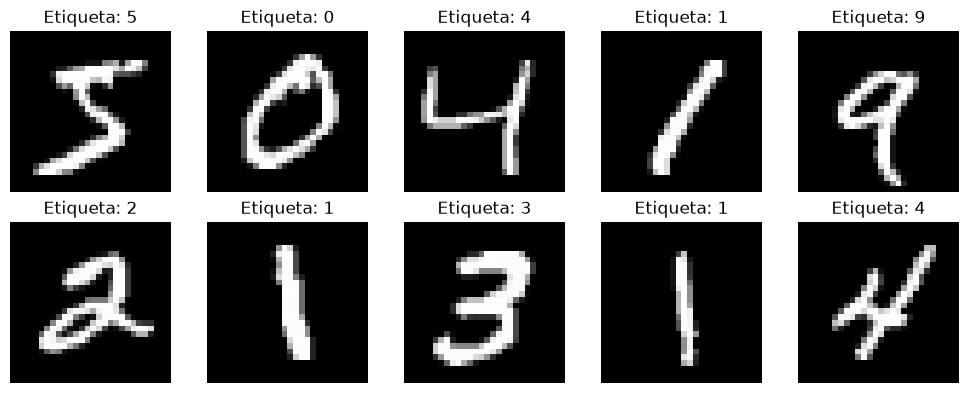

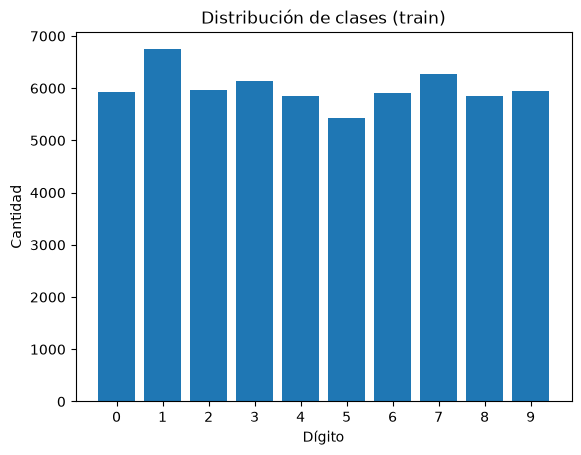

In [12]:
# Inspeccionamos imágenes etiquetadas y el balance de las diez clases.

figure, subplots = plt.subplots(2, 5, figsize=(10, 4))
for index, plot_axis in enumerate(subplots.flat):
    plot_axis.imshow(train_images_raw[index], cmap="gray"); plot_axis.set_title(f"Etiqueta: {train_labels[index]}"); plot_axis.axis("off")
plt.tight_layout(); plt.show()

plt.bar(range(10), np.bincount(train_labels)); plt.xticks(range(10))
plt.xlabel("Dígito"); plt.ylabel("Cantidad"); plt.title("Distribución de clases (train)"); plt.show()

In [13]:
# Aplanamos cada imagen, normalizamos píxeles y codificamos etiquetas en formato one-hot.

# Cada fila pasa a ser un vector de 784 píxeles; dividir por 255 escala los valores a [0, 1].
train_inputs = train_images_raw.reshape(len(train_images_raw), -1).astype(np.float64) / 255.0   # (60000, 784)
test_inputs  = test_images_raw.reshape(len(test_images_raw), -1).astype(np.float64) / 255.0     # (10000, 784)

def one_hot(class_labels, class_count=10):
    """Convierte cada etiqueta entera en un vector con un único 1."""
    one_hot_targets = np.zeros((class_labels.shape[0], class_count))
    one_hot_targets[np.arange(class_labels.shape[0]), class_labels] = 1
    return one_hot_targets

train_targets, test_targets = one_hot(train_labels), one_hot(test_labels)
print("train_inputs:", train_inputs.shape, "| train_targets:", train_targets.shape)

train_inputs: (60000, 784) | train_targets: (60000, 10)


## 2. Implementación desde cero

**Capa densa:** $Z = XW + b$ con $X \in \mathbb{R}^{N\times n_{in}}$, $W \in \mathbb{R}^{n_{in}\times n_{out}}$, $b \in \mathbb{R}^{n_{out}}$.

**ReLU:** $A = \max(0, Z)$, derivada $\frac{\partial A}{\partial Z} = 1$ si $Z>0$, y $0$ en otro caso.

**Softmax:** $p_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$ (se resta $\max(z)$ por estabilidad numérica).

**Cross-Entropy:** $L = -\frac{1}{N}\sum_{i}\sum_k y_{ik}\log p_{ik}$

In [14]:
# Componentes matemáticos de la red: capas densas, ReLU, Softmax y entropía cruzada.

class Dense:
    def __init__(self, input_size, output_size):
        # He mantiene una escala razonable de activaciones al usar ReLU.
        self.weights = np.random.randn(input_size, output_size) * np.sqrt(2.0 / input_size)
        self.biases = np.zeros((1, output_size))
        self.weight_gradients = np.zeros_like(self.weights)
        self.bias_gradients = np.zeros_like(self.biases)

    def forward(self, inputs):
        self.inputs = inputs  # Se conserva para calcular los gradientes en backward.
        return inputs @ self.weights + self.biases       # (N, input_size) @ (input_size, output_size) -> (N, output_size)

    def backward(self, logit_gradients):
        # dL/dW = entrada transpuesta @ dL/dlogits; el resultado tiene la forma de W.
        self.weight_gradients = self.inputs.T @ logit_gradients                    # (input_size, N) @ (N, output_size)
        # El bias se comparte entre ejemplos, por eso sumamos el gradiente del lote.
        self.bias_gradients = logit_gradients.sum(axis=0, keepdims=True)    # (1, output_size)
        return logit_gradients @ self.weights.T                       # Devuelve el gradiente respecto de las entradas de esta capa.

class ReLU:
    def forward(self, logits):
        # La máscara permite que backward pase gradiente solo donde la entrada fue positiva.
        self.mask = logits > 0
        return logits * self.mask

    def backward(self, activation_gradients):
        return activation_gradients * self.mask

def softmax(logits):
    # Restar el máximo no cambia Softmax y evita exponenciales demasiado grandes.
    logits = logits - logits.max(axis=1, keepdims=True)
    exp_logits = np.exp(logits)
    return exp_logits / exp_logits.sum(axis=1, keepdims=True)

def cross_entropy(probabilities, targets, epsilon=1e-12):
    return -np.mean(np.sum(targets * np.log(probabilities + epsilon), axis=1))

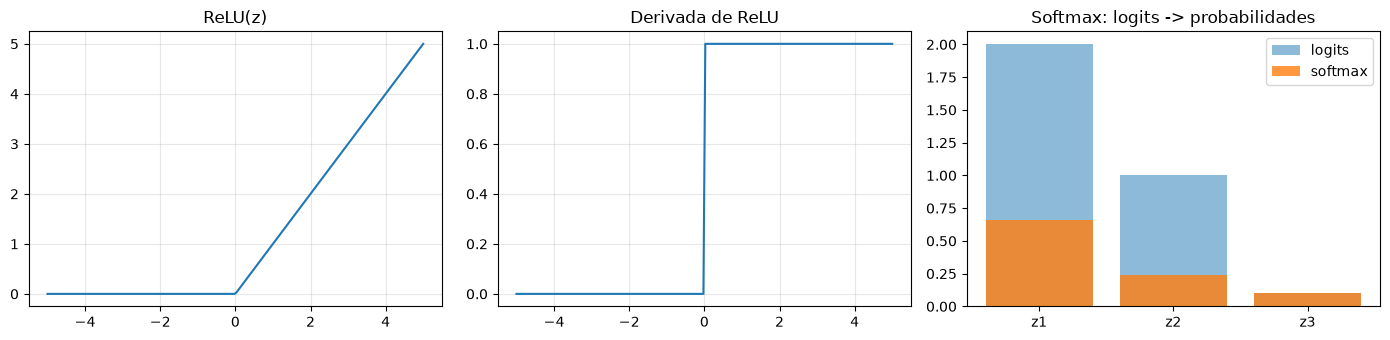

Suma de probabilidades: 1.0


In [15]:
# Graficamos ReLU, su derivada y Softmax aplicado a logits de ejemplo.

# Visualización de ReLU y Softmax
logit_values = np.linspace(-5, 5, 200)
relu_outputs = np.maximum(0, logit_values)
example_logits = np.array([[2.0, 1.0, 0.1]])

figure, plot_axis = plt.subplots(1, 3, figsize=(14, 3.5))
plot_axis[0].plot(logit_values, relu_outputs); plot_axis[0].set_title("ReLU(z)"); plot_axis[0].grid(alpha=.3)
plot_axis[1].plot(logit_values, (logit_values > 0).astype(float)); plot_axis[1].set_title("Derivada de ReLU"); plot_axis[1].grid(alpha=.3)
plot_axis[2].bar(["z1", "z2", "z3"], example_logits[0], alpha=.5, label="logits")
plot_axis[2].bar(["z1", "z2", "z3"], softmax(example_logits)[0], alpha=.8, label="softmax")
plot_axis[2].set_title("Softmax: logits -> probabilidades"); plot_axis[2].legend()
plt.tight_layout(); plt.show()
print("Suma de probabilidades:", softmax(example_logits).sum())

## 3. Entrenamiento y Backpropagation

Red: `784 → 128 → 64 → 10` (ReLU en las ocultas, Softmax en la salida).

**Regla de la cadena, capa por capa (hacia atrás):**

1. **Softmax + Cross-Entropy.** Combinando ambas, la derivada se simplifica: $\frac{\partial L}{\partial Z_3} = \frac{1}{N}(P - Y)$
2. **Capa densa** $Z = AW + b$:
   $\frac{\partial L}{\partial W} = A^\top \frac{\partial L}{\partial Z}$, $\quad \frac{\partial L}{\partial b} = \sum_i \frac{\partial L}{\partial Z_i}$, $\quad \frac{\partial L}{\partial A} = \frac{\partial L}{\partial Z} W^\top$
3. **ReLU:** $\frac{\partial L}{\partial Z} = \frac{\partial L}{\partial A} \odot \mathbb{1}[Z>0]$
4. Se repite hasta la primera capa y se actualiza con **SGD**: $W \leftarrow W - \eta\,\frac{\partial L}{\partial W}$

In [16]:
# La red encadena capas densas; backward propaga gradientes usando la regla de la cadena.

class Network:
    def __init__(self, layer_sizes):
        self.dense = [Dense(layer_sizes[index], layer_sizes[index + 1]) for index in range(len(layer_sizes) - 1)]
        self.relus = [ReLU() for relu_index in range(len(layer_sizes) - 2)]

    def forward(self, inputs):
        activations = inputs
        for index, layer in enumerate(self.dense):
            logits = layer.forward(activations)
            activations = self.relus[index].forward(logits) if index < len(self.relus) else logits
        return softmax(activations)

    def backward(self, probabilities, targets):
        # Softmax + cross-entropy: gradiente de logits promediado sobre el lote.
        logit_gradients = (probabilities - targets) / targets.shape[0]                    # Softmax + CE
        for index in reversed(range(len(self.dense))):
            if index < len(self.relus):
                logit_gradients = self.relus[index].backward(logit_gradients)      # a través de ReLU
            logit_gradients = self.dense[index].backward(logit_gradients)          # Dense devuelve el gradiente respecto de las activaciones previas.

    def sgd_step(self, learning_rate):
        # Descenso de gradiente: movemos cada parámetro contra la dirección de mayor aumento de pérdida.
        for layer in self.dense:
            layer.weights -= learning_rate * layer.weight_gradients
            layer.biases -= learning_rate * layer.bias_gradients

    def predict(self, inputs):
        return np.argmax(self.forward(inputs), axis=1)

In [17]:
# Entrenamos por mini-lotes: forward, gradientes, actualización SGD y métricas por epoch.

def accuracy(probabilities, class_labels):
    return np.mean(np.argmax(probabilities, axis=1) == class_labels)

network = Network([784, 128, 64, 10])
epochs, batch_size, learning_rate = 15, 128, 0.1
history = {"loss": [], "acc": [], "val_loss": [], "val_acc": []}

for epoch in range(epochs):
    # Barajar cada epoch evita que el orden fijo de los ejemplos sesgue los mini-lotes.
    shuffled_indices = np.random.permutation(len(train_inputs))
    shuffled_inputs, shuffled_targets = train_inputs[shuffled_indices], train_targets[shuffled_indices]
    for index in range(0, len(shuffled_inputs), batch_size):
        batch_inputs, batch_targets = shuffled_inputs[index:index + batch_size], shuffled_targets[index:index + batch_size]
        probabilities = network.forward(batch_inputs)
        network.backward(probabilities, batch_targets)
        network.sgd_step(learning_rate)

    # Medimos métricas después de completar todas las actualizaciones de este epoch.
    train_probabilities = network.forward(train_inputs); test_probabilities = network.forward(test_inputs)
    history["loss"].append(cross_entropy(train_probabilities, train_targets)); history["acc"].append(accuracy(train_probabilities, train_labels))
    history["val_loss"].append(cross_entropy(test_probabilities, test_targets)); history["val_acc"].append(accuracy(test_probabilities, test_labels))
    print(f"Epoch {epoch+1:2d}/{epochs} | loss {history['loss'][-1]:.4f} | acc {history['acc'][-1]:.4f} "
          f"| test loss {history['val_loss'][-1]:.4f} | test acc {history['val_acc'][-1]:.4f}")

Epoch  1/15 | loss 0.2339 | acc 0.9322 | test loss 0.2327 | test acc 0.9344
Epoch  2/15 | loss 0.1665 | acc 0.9526 | test loss 0.1699 | test acc 0.9498
Epoch  3/15 | loss 0.1324 | acc 0.9624 | test loss 0.1399 | test acc 0.9582
Epoch  4/15 | loss 0.1016 | acc 0.9710 | test loss 0.1121 | test acc 0.9656
Epoch  5/15 | loss 0.0909 | acc 0.9738 | test loss 0.1071 | test acc 0.9672
Epoch  6/15 | loss 0.0741 | acc 0.9793 | test loss 0.0944 | test acc 0.9712
Epoch  7/15 | loss 0.0672 | acc 0.9809 | test loss 0.0922 | test acc 0.9713
Epoch  8/15 | loss 0.0555 | acc 0.9845 | test loss 0.0817 | test acc 0.9749
Epoch  9/15 | loss 0.0543 | acc 0.9846 | test loss 0.0878 | test acc 0.9735
Epoch 10/15 | loss 0.0480 | acc 0.9864 | test loss 0.0831 | test acc 0.9746
Epoch 11/15 | loss 0.0398 | acc 0.9890 | test loss 0.0757 | test acc 0.9761
Epoch 12/15 | loss 0.0372 | acc 0.9903 | test loss 0.0789 | test acc 0.9758
Epoch 13/15 | loss 0.0314 | acc 0.9919 | test loss 0.0746 | test acc 0.9761
Epoch 14/15 

## 4. Evaluación

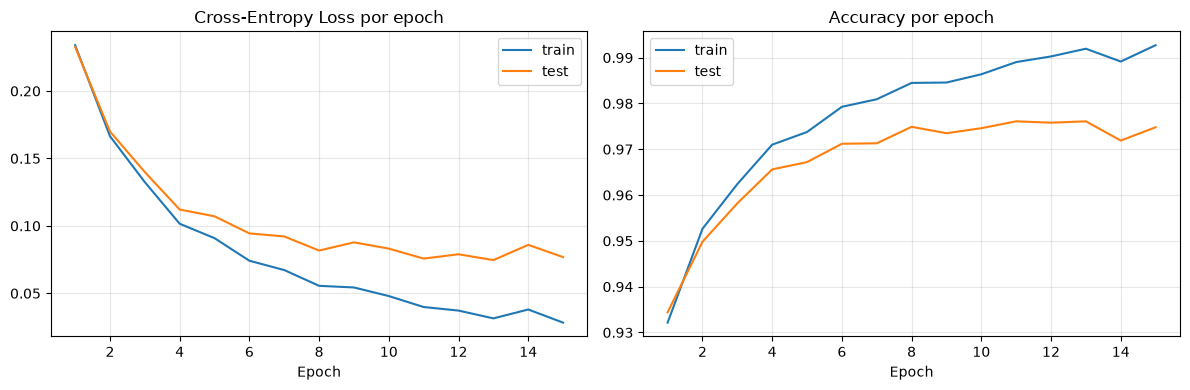

Test accuracy: 0.9748


In [18]:
# Graficamos el aprendizaje y medimos el rendimiento final en test.

epoch_numbers = range(1, epochs + 1)
figure, plot_axis = plt.subplots(1, 2, figsize=(12, 4))
plot_axis[0].plot(epoch_numbers, history["loss"], label="train"); plot_axis[0].plot(epoch_numbers, history["val_loss"], label="test")
plot_axis[0].set_title("Cross-Entropy Loss por epoch"); plot_axis[0].set_xlabel("Epoch"); plot_axis[0].legend(); plot_axis[0].grid(alpha=.3)
plot_axis[1].plot(epoch_numbers, history["acc"], label="train"); plot_axis[1].plot(epoch_numbers, history["val_acc"], label="test")
plot_axis[1].set_title("Accuracy por epoch"); plot_axis[1].set_xlabel("Epoch"); plot_axis[1].legend(); plot_axis[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

predicted_labels = network.predict(test_inputs)
print(f"Test accuracy: {np.mean(predicted_labels == test_labels):.4f}")

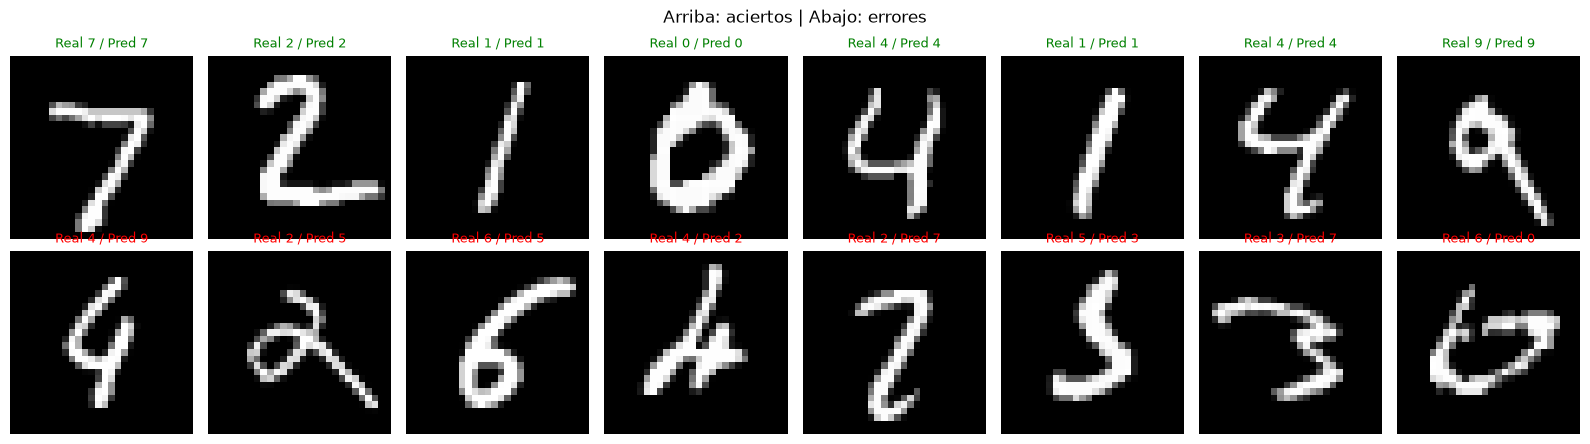

In [19]:
# Comparamos visualmente algunas predicciones correctas e incorrectas.

# Ejemplos de aciertos y errores
correct_indices = np.where(predicted_labels == test_labels)[0]
incorrect_indices = np.where(predicted_labels != test_labels)[0]
figure, subplots = plt.subplots(2, 8, figsize=(16, 4.5))
for plot_axis, index in zip(subplots[0], correct_indices[:8]):
    plot_axis.imshow(test_images_raw[index], cmap="gray"); plot_axis.set_title(f"Real {test_labels[index]} / Pred {predicted_labels[index]}", color="green", fontsize=9); plot_axis.axis("off")
for plot_axis, index in zip(subplots[1], incorrect_indices[:8]):
    plot_axis.imshow(test_images_raw[index], cmap="gray"); plot_axis.set_title(f"Real {test_labels[index]} / Pred {predicted_labels[index]}", color="red", fontsize=9); plot_axis.axis("off")
plt.suptitle("Arriba: aciertos | Abajo: errores"); plt.tight_layout(); plt.show()

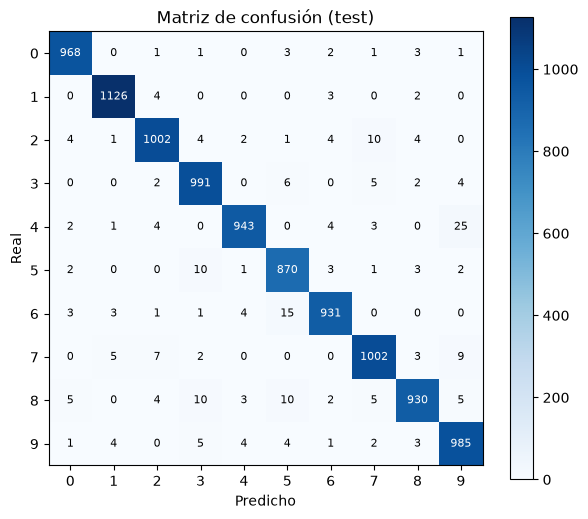

Dígito con más errores: 8 (44 errores de 974)
Confusión más frecuente: 4 predicho como 9 (25 veces)


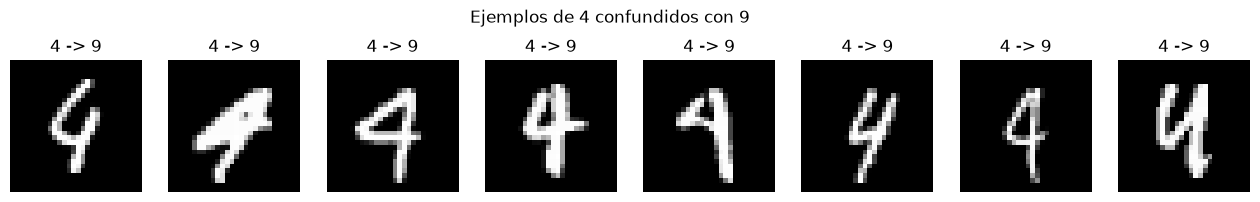

In [ ]:
# Construimos la matriz de confusión y buscamos los errores más frecuentes.

# Matriz de confusión manual
confusion_matrix = np.zeros((10, 10), dtype=int)
for actual_label, predicted_label in zip(test_labels, predicted_labels):
    confusion_matrix[actual_label, predicted_label] += 1

plt.figure(figsize=(7, 6))
plt.imshow(confusion_matrix, cmap="Blues"); plt.colorbar()
for actual_digit in range(10):
    for predicted_digit in range(10):
        plt.text(predicted_digit, actual_digit, confusion_matrix[actual_digit, predicted_digit], ha="center", va="center", fontsize=8,
                 color="white" if confusion_matrix[actual_digit, predicted_digit] > confusion_matrix.max() / 2 else "black")
plt.xticks(range(10)); plt.yticks(range(10))
plt.xlabel("Predicho"); plt.ylabel("Real"); plt.title("Matriz de confusión (test)"); plt.show()

errors_per_digit = confusion_matrix.sum(axis=1) - np.diag(confusion_matrix)
most_mistaken_digit = np.argmax(errors_per_digit)
off_diagonal_counts = confusion_matrix.copy(); np.fill_diagonal(off_diagonal_counts, 0)
actual_digit, predicted_digit = np.unravel_index(np.argmax(off_diagonal_counts), off_diagonal_counts.shape)
print(f"Dígito con más errores: {most_mistaken_digit} ({errors_per_digit[most_mistaken_digit]} errores de {confusion_matrix[most_mistaken_digit].sum()})")
print(f"Confusión más frecuente: {actual_digit} predicho como {predicted_digit} ({off_diagonal_counts[actual_digit, predicted_digit]} veces)")

shuffled_indices = np.where((test_labels == actual_digit) & (predicted_labels == predicted_digit))[0][:8]
figure, subplots = plt.subplots(1, len(shuffled_indices), figsize=(2 * len(shuffled_indices), 2.4))
for plot_axis, index in zip(np.atleast_1d(subplots), shuffled_indices):
    plot_axis.imshow(test_images_raw[index], cmap="gray"); plot_axis.set_title(f"{actual_digit} -> {predicted_digit}"); plot_axis.axis("off")
plt.suptitle(f"Ejemplos de {actual_digit} confundidos con {predicted_digit}"); plt.show()

## 5. Conclusiones

- **Backprop es la regla de la cadena aplicada con orden:** cada capa recibe $\partial L/\partial(\text{su salida})$ y devuelve $\partial L/\partial(\text{su entrada})$, además de sus propios gradientes $dW$ y $db$.
- **Softmax + Cross-Entropy** produce el gradiente simple $(P - Y)/N$: la red se corrige en proporción a cuánto se equivocó.
- **Las shapes guían todo:** el gradiente de cada parámetro tiene siempre la misma shape que el parámetro, y las transposiciones salen de ahí.
- **Qué aprendí que antes no sabía:** `.fit()` es exactamente este bucle: forward, loss, backward y update. La estabilidad numérica (restar el máximo en Softmax, `eps` en el log) y la inicialización He importan en la práctica.
- **Errores:** las confusiones más frecuentes ocurren entre dígitos de trazo parecido (ver matriz de confusión), porque una red densa trata cada píxel de forma independiente y no aprovecha la estructura espacial. Una convolución sí la aprovecharía.

### Análisis concreto de la confusión más frecuente

En esta ejecución, la confusión individual más frecuente fue **4 → 9 (25 imágenes)**. La matriz también muestra que el **8** acumula más errores totales: **44 de 974** ejemplos reales de esa clase. Son dos medidas distintas: una cuenta el par de clases más confundido y la otra la clase con más fallos sumados.

Las imágenes 4→9 mostradas justo arriba permiten inspeccionar los casos concretos. Una explicación plausible es que algunos cuatros manuscritos tienen el trazo superior unido o una forma cerrada, y se parecen visualmente a nueves; al mismo tiempo, la capa densa procesa los píxeles aplanados y no representa explícitamente la continuidad de los trazos. Esta explicación es una hipótesis visual sobre esos ejemplos, no una causa demostrada por el modelo. Para comprobarla con más detalle, se podrían agrupar los errores por estilo de escritura o visualizar qué píxeles influyen más en cada predicción.

La matriz de confusión y las imágenes de 4→9 se calculan a partir de las predicciones de test de esta ejecución; si se vuelve a entrenar la red, los conteos pueden cambiar.